In [2]:
import os
from pathlib import Path
if not (Path.cwd() / "Risk_Modeling").exists():
    os.chdir("..")


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Shared_Utils.Data_Utils import load_data, remove_sparse_tickers
from Risk_Modeling.Risk_Kit.Factor_Risk_Model import risk
from Risk_Modeling.Risk_Kit.Risk_Kit_Utils.Risk_Model_Harness import multiple_model_tracker,run_multiple_risk_models


%load_ext autoreload
%autoreload 2

In [3]:
def random_long_portfolio(n_assets,current_data):
    portfolio=current_data[["Date","Ticker","PCT_Return"]]
    hypothetical_weight=np.random.rand(len(current_data))
    selected_weight = np.zeros_like(hypothetical_weight)
    idx = np.random.choice(len(hypothetical_weight), size=n_assets, replace=False)
    selected_weight[idx] = hypothetical_weight[idx]
    portfolio["Weight"]=selected_weight/selected_weight.sum()
    
    individual_return=portfolio["Weight"]*portfolio["PCT_Return"]
    realized_return=float(individual_return.sum())
    portfolio.drop("Weight",axis=1)
    return portfolio, realized_return

# Risk Modeling

In [4]:
df=load_data()
all_dates=df["Date"].unique()

In [ ]:
models_dict={

            "Basic model":risk(),
            **{f"Basic model {i} month halflife": risk(ewma_halflife=i) for i in range(1, 13)},

            "Fundamental factor model":risk(fundamental_factor_model=True),
            **{f"Fundamental factor model {i} month halflife": risk(fundamental_factor_model=True, ewma_halflife=i) for i in range(1, 13)},

            "PCA factor model":risk(pca_factor_model=True),
            **{f"PCA factor model {i} month halflife": risk(pca_factor_model=True, ewma_halflife=i) for i in range(1, 13)},

            "Ledoit-wolf model":risk(ledoit_wolf=True),
            **{f"Ledoit-wolf model {i} month halflife": risk(ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},

            "Fundamental factor model Ledoit-Wolf":risk(fundamental_factor_model=True,ledoit_wolf=True),
            **{f"Fundamental factor model Ledoit-Wolf {i} month halflife": risk(fundamental_factor_model=True, ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},

            "PCA factor model Ledoit-Wolf":risk(pca_factor_model=True,ledoit_wolf=True),
            **{f"PCA factor model Ledoit-Wolf {i} month halflife": risk(pca_factor_model=True, ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},
}


n_assets=[400,200,100,50,20,10] #number of assets in each random portfolio
n_assets=[400] #number of assets in each random portfolio
trackers={n:multiple_model_tracker(models_dict) for n in n_assets}

seed_number=1
lookback=60
for i, date in enumerate(all_dates):
    print(f"\r{date}", end="", flush=True)
    if i<lookback:
        continue

    # Select historical PIT data 
    historical_data=df[(df["Date"]<date) & (df["Date"]>=all_dates[i-lookback])]
    historical_data,valid_tickers=remove_sparse_tickers(historical_data)
    average_return=historical_data.pivot(index="Date",columns="Ticker",values="PCT_Return").mean()
    average_return.name="AVG_Return"
    
    # Run risk models on historical data
    models_dict=run_multiple_risk_models(models_dict,historical_data)
    # Identify current data
    current_data=df[df["Date"]==date]
    current_data=current_data[current_data["Ticker"].isin(valid_tickers)]

    
    for n in n_assets:
        #Create a random diversified portfolio
        np.random.seed(seed_number);seed_number+=1
        portfolio,realized_return=random_long_portfolio(n,current_data)

        
        excess_portfolio=portfolio[["Ticker","Weight","PCT_Return"]].merge(average_return,on="Ticker",how="left")
        excess_portfolio["Excess_return"]=excess_portfolio["PCT_Return"]-excess_portfolio["AVG_Return"]
        excess_return=(excess_portfolio["Excess_return"]*excess_portfolio["Weight"]).sum()

        # Update tracking
        trackers[n].append_multiple_variance_estimates(date,models_dict,current_data,portfolio)
        trackers[n].append_multiple_realized_systematic_returns(date,models_dict,current_data,portfolio)
        trackers[n].append_realized_return(date,realized_return)
        trackers[n].append_excess_return(date,excess_return)

2025-12-31 00:00:00

In [38]:
for n in n_assets:
    print(f"Performance Summary for Portfolio with {n} Assets:")
    with pd.option_context('display.max_rows', None):
        display(trackers[n].performance_summary(models_dict))
    print("\n")

Performance Summary for Portfolio with 400 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Fundamental factor model Ledoit-Wolf,-0.07619,0.99857,0.986329,-0.372174,0.353906


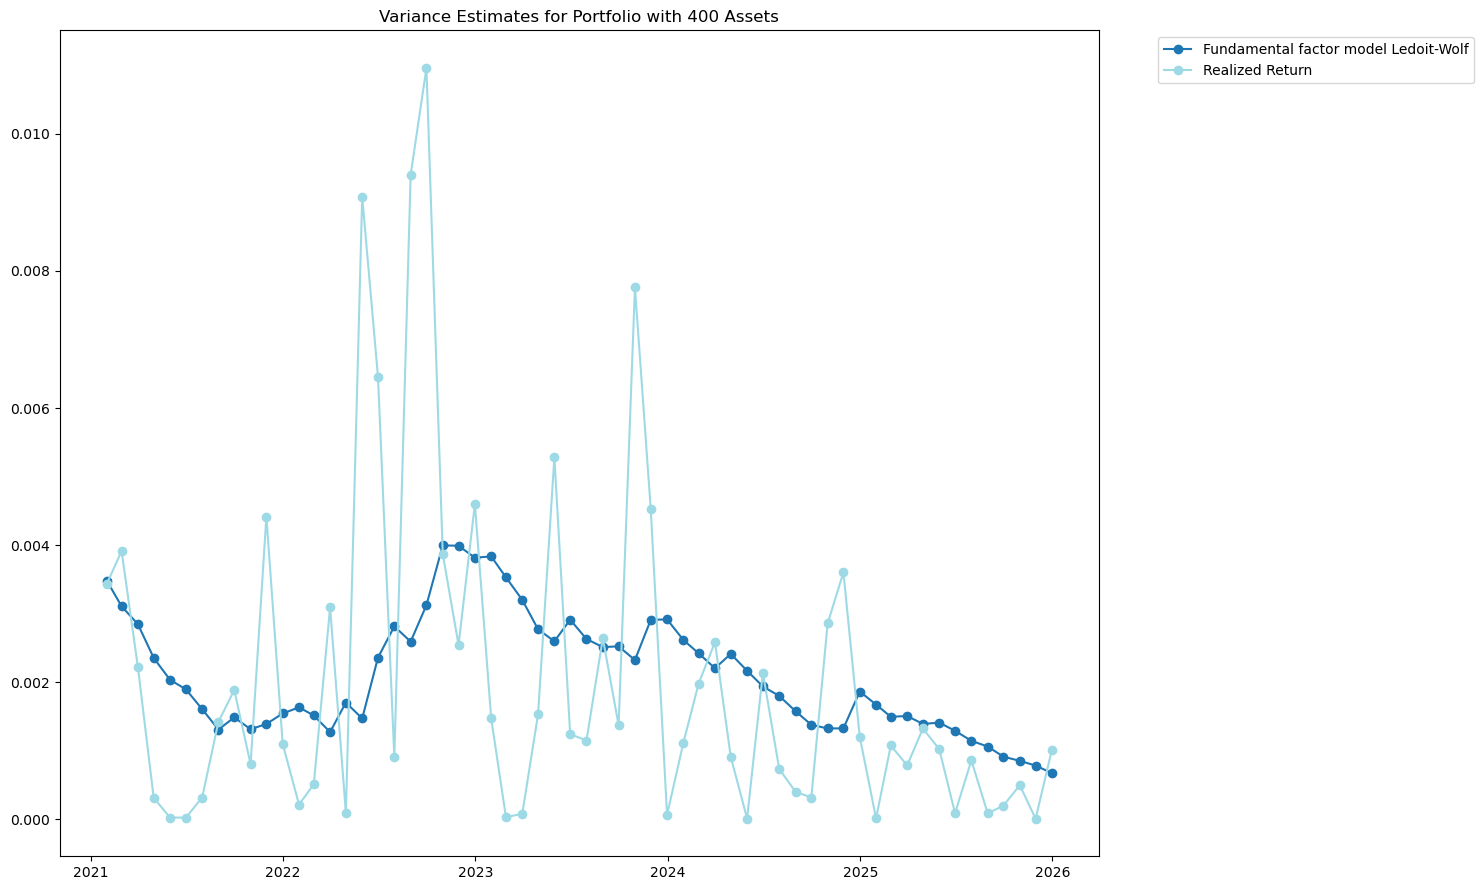

In [39]:
for n in n_assets:
    plot_volatility_estimates(trackers[n],models_dict,n)
    print("\n")

# Results

In [100]:
for n in n_assets:
    print(f"Performance Summary for Portfolio with {n} Assets:")
    with pd.option_context('display.max_rows', None):
        display(trackers[n].performance_summary(models_dict))
    print("\n")

Performance Summary for Portfolio with 400 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Basic model,-0.029498,0.839814,0.694402,-0.462670,4.835236e-01
Basic model 1 month halflife,-0.074561,1.157314,1.322613,-0.274134,7.302922e-01
Basic model 2 month halflife,-0.065329,1.025035,1.037452,-0.389177,5.107317e-01
Basic model 3 month halflife,-0.063874,0.974605,0.938105,-0.329870,3.472023e-01
Basic model 4 month halflife,-0.060578,0.939882,0.872325,-0.341584,3.011065e-01
Basic model 5 month halflife,-0.056804,0.914135,0.824942,-0.377127,2.935488e-01
Basic model 6 month halflife,-0.053381,0.894974,0.790479,-0.411549,3.175330e-01
Basic model 7 month halflife,-0.050501,0.880653,0.765174,-0.438655,3.550580e-01
Basic model 8 month halflife,-0.048127,0.869856,0.746354,-0.458656,3.827193e-01
Basic model 9 month halflife,-0.046173,0.861631,0.732167,-0.473112,4.059540e-01




Performance Summary for Portfolio with 200 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Basic model,-0.016330,0.836576,0.688462,-0.321327,0.773689
Basic model 1 month halflife,-0.076860,1.125165,1.250803,-0.397110,0.407151
Basic model 2 month halflife,-0.063376,1.011930,1.010952,-0.410140,0.325971
Basic model 3 month halflife,-0.060034,0.966350,0.921872,-0.314654,0.347687
Basic model 4 month halflife,-0.055817,0.934385,0.861639,-0.295340,0.389393
Basic model 5 month halflife,-0.051410,0.910376,0.817614,-0.301965,0.483802
Basic model 6 month halflife,-0.047438,0.892170,0.784952,-0.314634,0.527215
Basic model 7 month halflife,-0.044055,0.878300,0.760494,-0.326914,0.566323
Basic model 8 month halflife,-0.041222,0.867669,0.742002,-0.337113,0.616057
Basic model 9 month halflife,-0.038853,0.859464,0.727877,-0.345086,0.659995




Performance Summary for Portfolio with 100 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Basic model,-0.051827,0.855367,0.722145,-0.506684,0.581763
Basic model 1 month halflife,-0.109016,1.179696,1.380373,-0.073253,0.683458
Basic model 2 month halflife,-0.099142,1.037502,1.068300,-0.498355,0.570806
Basic model 3 month halflife,-0.092868,0.980987,0.954922,-0.520224,0.344480
Basic model 4 month halflife,-0.086715,0.947161,0.889682,-0.513630,0.326702
Basic model 5 month halflife,-0.081386,0.923621,0.845482,-0.517187,0.345317
Basic model 6 month halflife,-0.077052,0.906319,0.813661,-0.525819,0.372343
Basic model 7 month halflife,-0.073603,0.893319,0.790135,-0.534481,0.383617
Basic model 8 month halflife,-0.070859,0.883423,0.772450,-0.541462,0.396410
Basic model 9 month halflife,-0.068656,0.875812,0.758976,-0.546593,0.416671


... (2 outputs left out)



Performance Summary for Portfolio with 20 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Basic model,-0.061675,0.767845,0.583563,-0.158937,0.524474
Basic model 1 month halflife,-0.142409,1.023659,1.050693,0.410820,0.441979
Basic model 2 month halflife,-0.115882,0.898831,0.807861,0.141824,0.345710
Basic model 3 month halflife,-0.108081,0.859209,0.737618,0.180314,0.199454
Basic model 4 month halflife,-0.102240,0.832689,0.692268,0.134496,0.170146
Basic model 5 month halflife,-0.096960,0.812198,0.658072,0.048752,0.171912
Basic model 6 month halflife,-0.092378,0.796574,0.632488,-0.031887,0.175187
Basic model 7 month halflife,-0.088540,0.784854,0.613568,-0.094731,0.183109
Basic model 8 month halflife,-0.085368,0.776112,0.599599,-0.140552,0.190857
Basic model 9 month halflife,-0.082749,0.769590,0.589245,-0.173174,0.195742




Performance Summary for Portfolio with 10 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Basic model,0.059511,0.945316,0.882271,-0.550673,0.785972
Basic model 1 month halflife,0.048707,1.263363,1.571858,0.635360,0.327746
Basic model 2 month halflife,0.035019,1.111737,1.216586,-0.022574,0.716577
Basic model 3 month halflife,0.033152,1.056565,1.098824,-0.170536,0.580533
Basic model 4 month halflife,0.034289,1.023748,1.031768,-0.276052,0.506409
Basic model 5 month halflife,0.036441,1.000611,0.985864,-0.360927,0.556813
Basic model 6 month halflife,0.038773,0.983630,0.952905,-0.423953,0.599490
Basic model 7 month halflife,0.040943,0.971019,0.928840,-0.469098,0.622945
Basic model 8 month halflife,0.042846,0.961595,0.911089,-0.501194,0.638221
Basic model 9 month halflife,0.044476,0.954510,0.897883,-0.524113,0.653341


In [29]:
def plot_volatility_estimates(tracker,models_dict,number_of_assets):
    vol_cloud=[]
    for i,model in enumerate(models_dict):
        vol=pd.DataFrame(tracker.variance_estimates[model]).iloc[0]
        vol.name=model
        vol_cloud.append(vol)
    vol_cloud=pd.concat(vol_cloud,axis=1)
    cmap = plt.colormaps['tab20']
    plt.figure(figsize=(15, 9))
    colors = [cmap(i / (len(models_dict)+1 - 1)) for i in range(len(models_dict)+1)]
    for i,col in enumerate(vol_cloud):
        plt.plot(vol_cloud[col],color=colors[i],label=col,marker='o')
    plt.plot(pd.DataFrame(tracker.realized_returns).iloc[0]**2,color=colors[i+1],label="Realized Return",marker='o')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(f"Variance Estimates for Portfolio with {number_of_assets} Assets")
    plt.tight_layout()
    plt.show()

C:\Users\cblev\AppData\Local\Temp\ipykernel_3576\3337784882.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


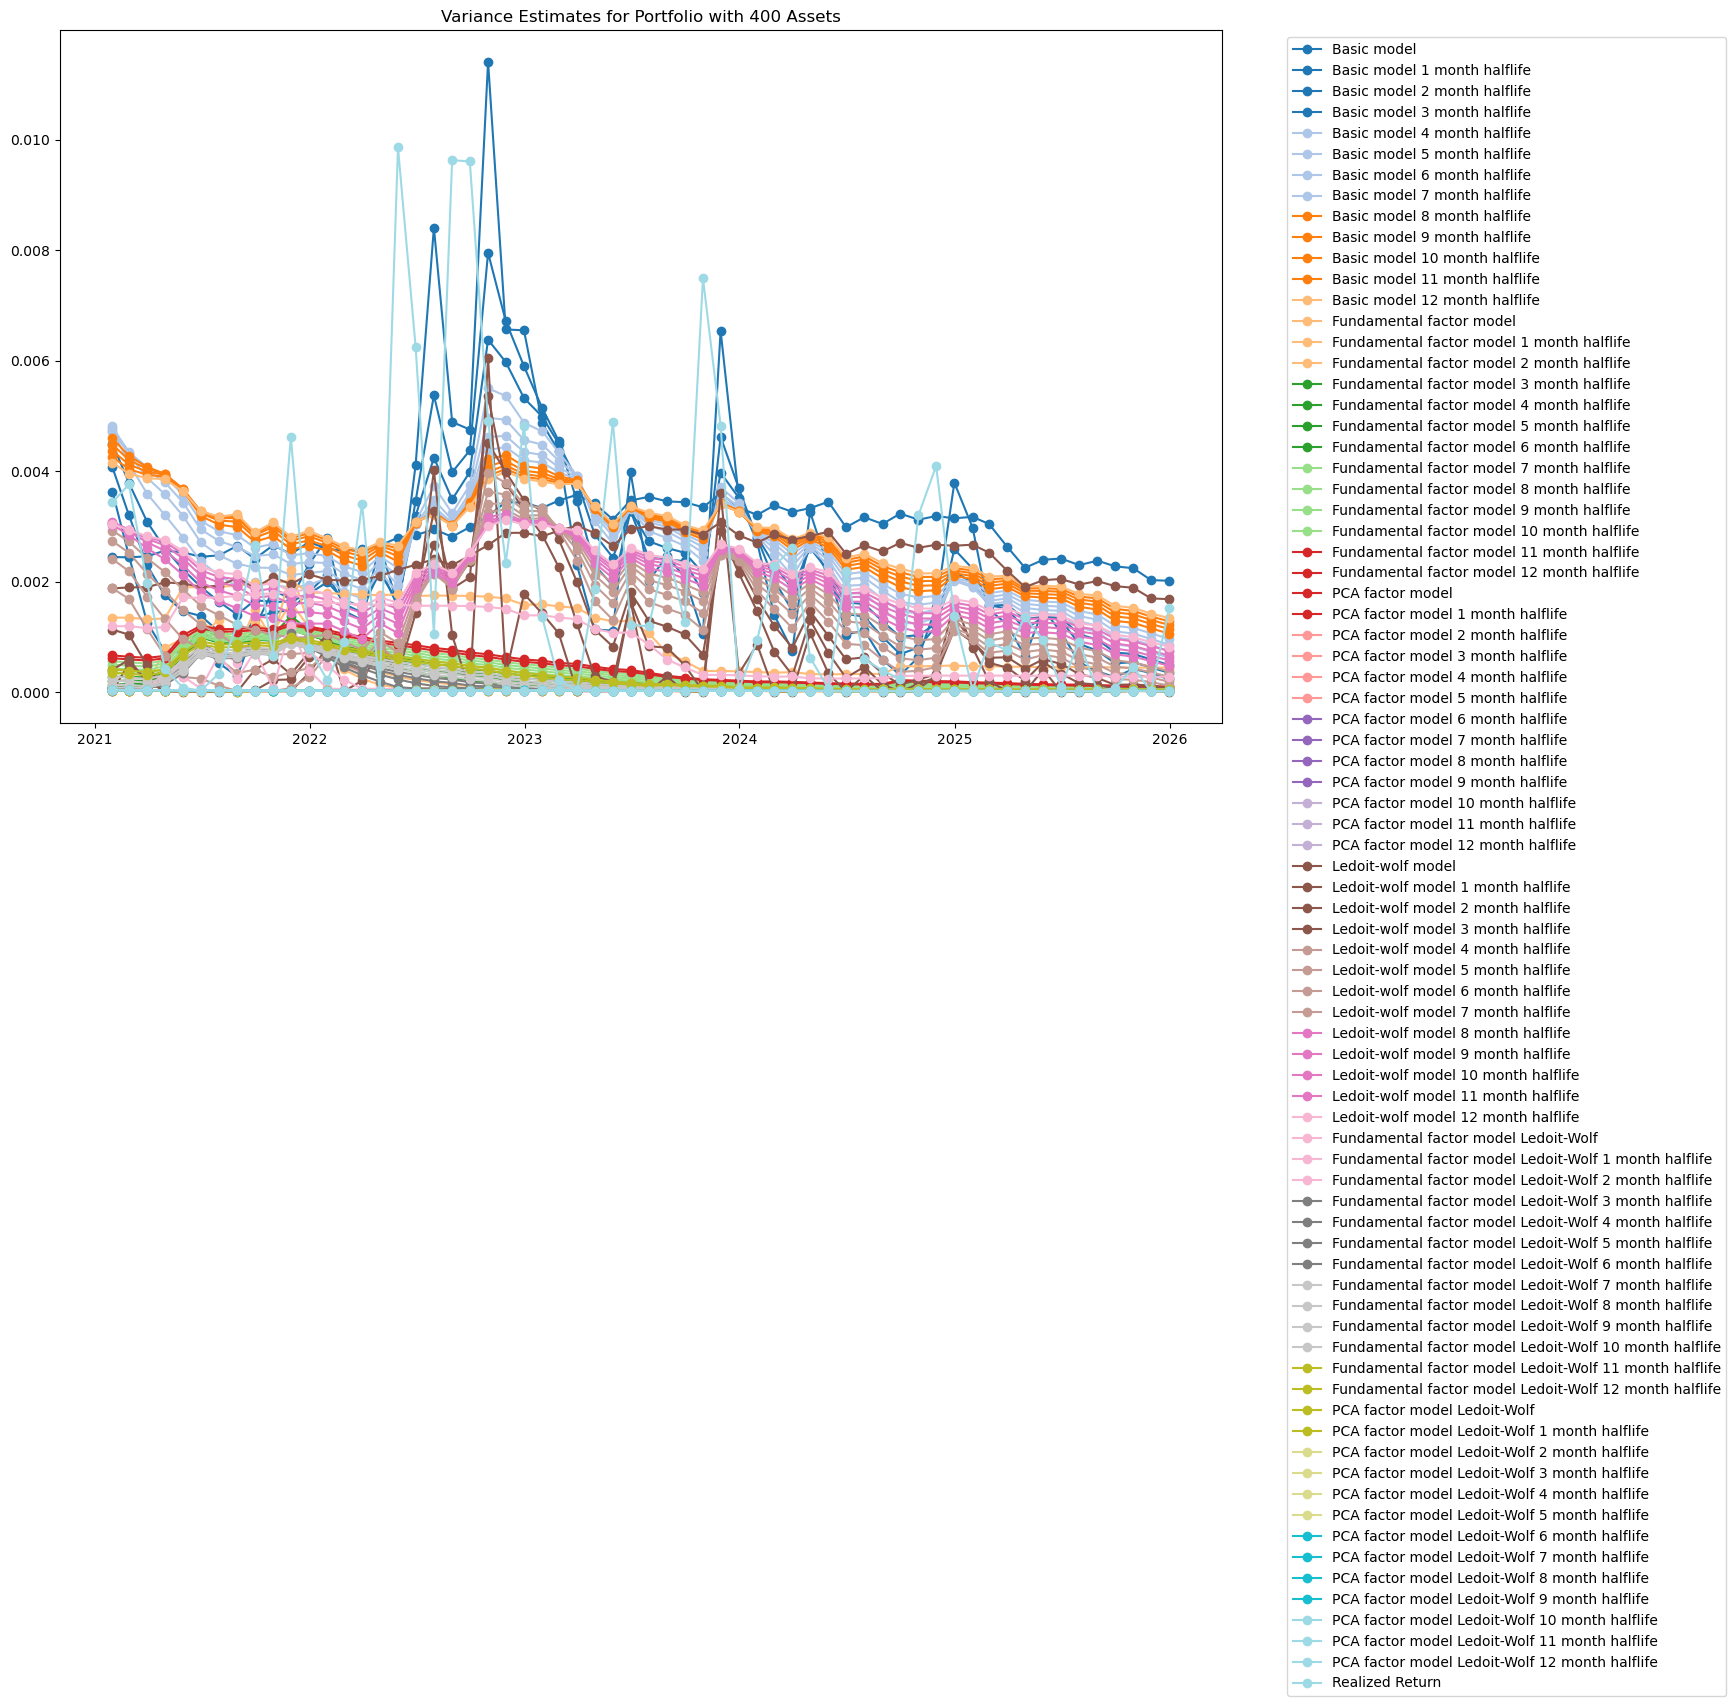

C:\Users\cblev\AppData\Local\Temp\ipykernel_3576\3337784882.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


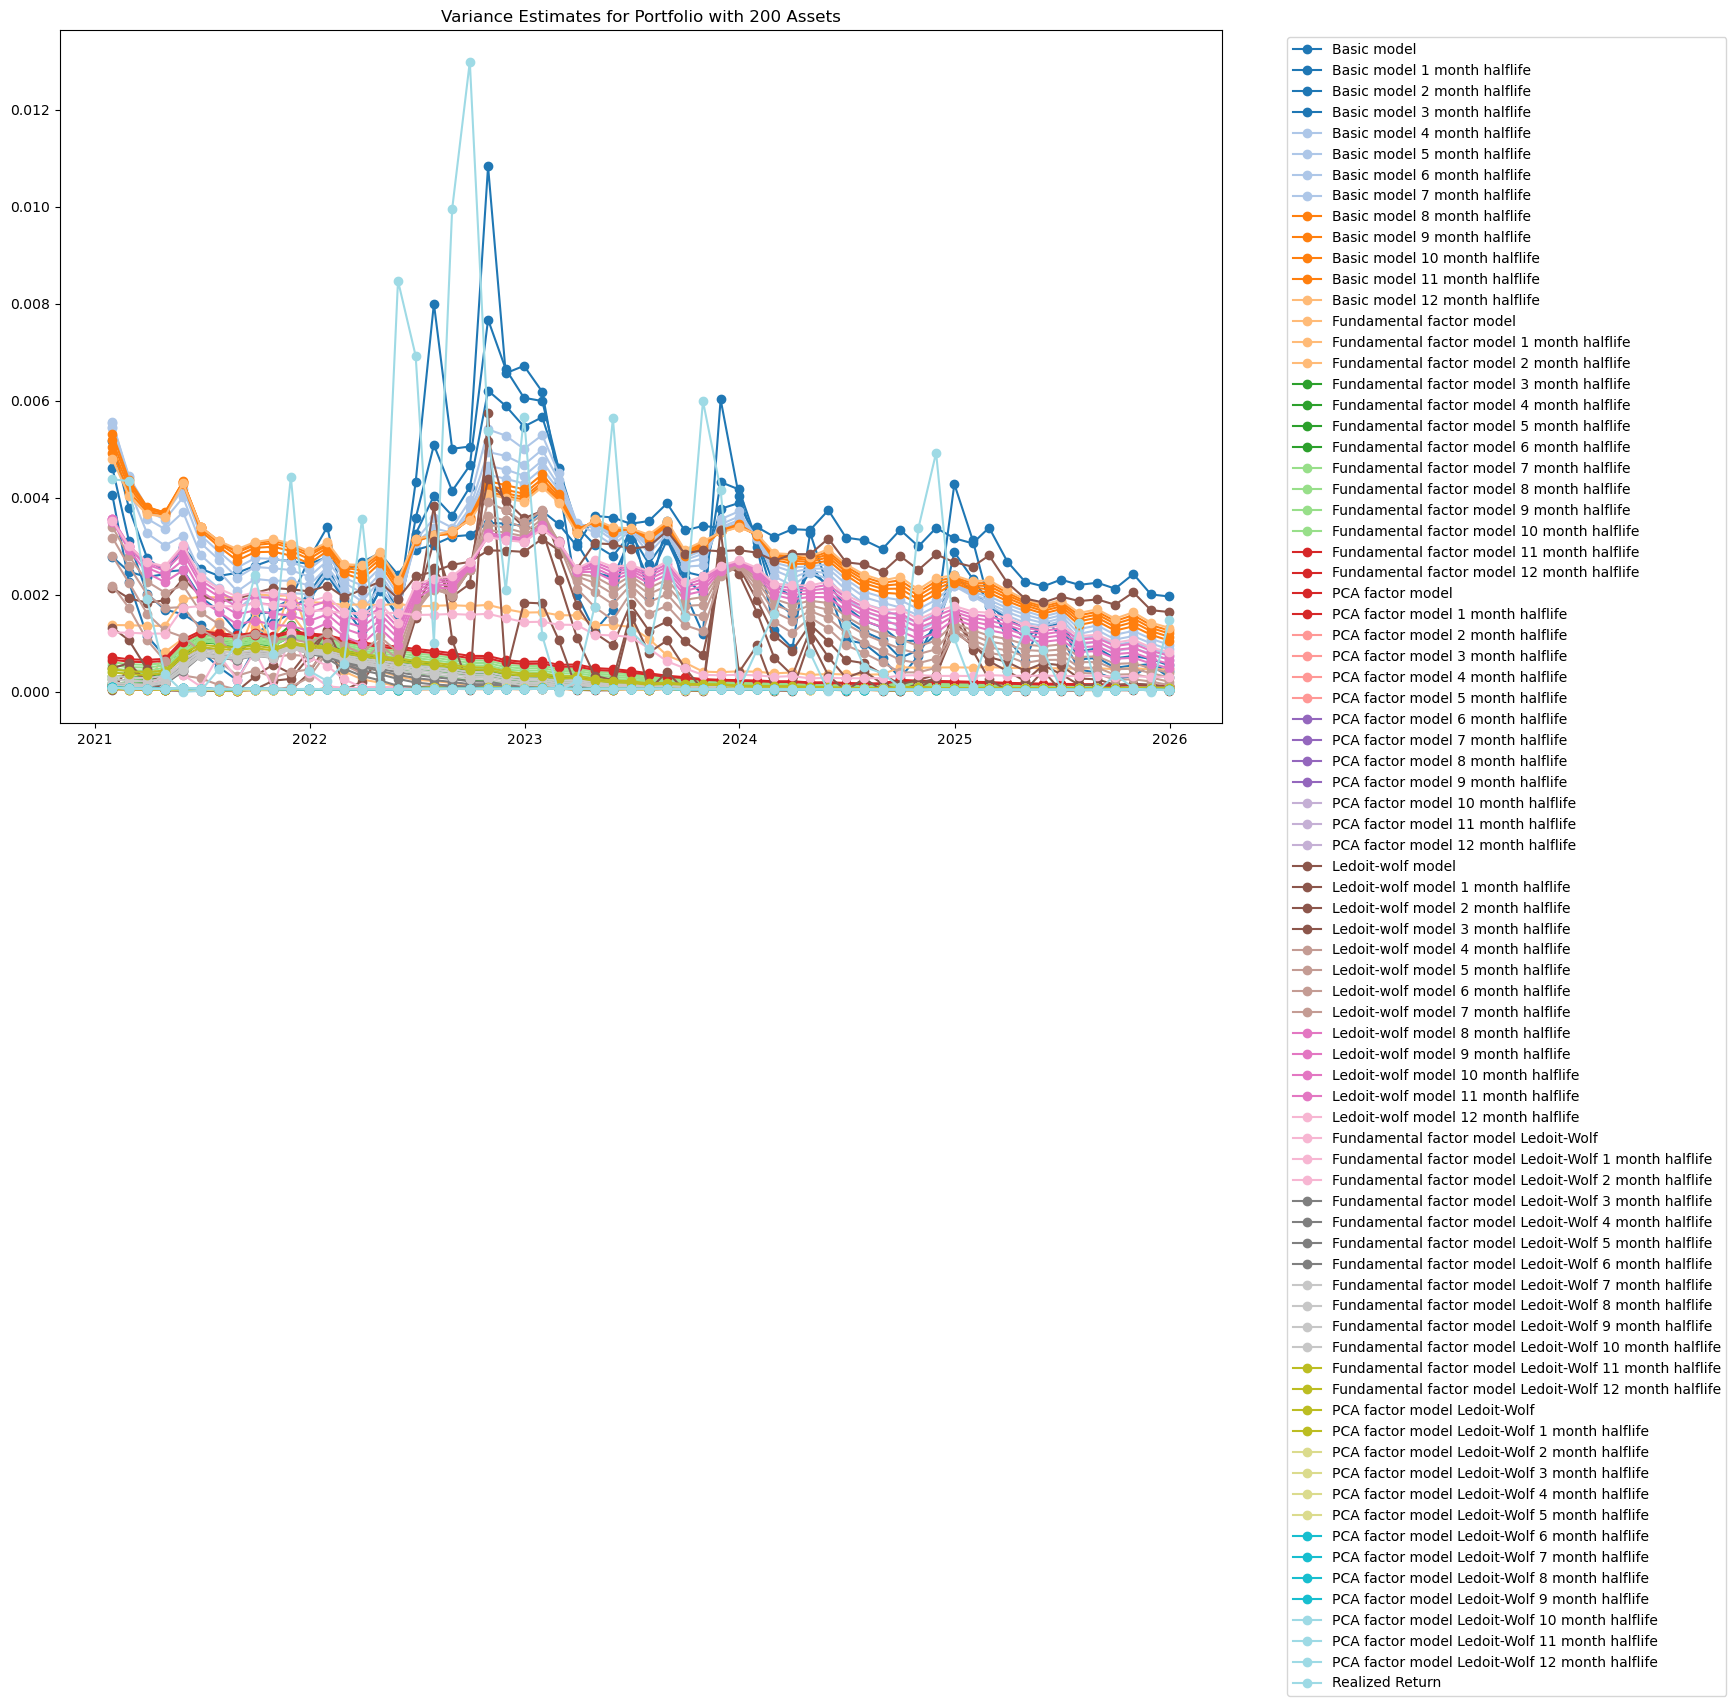

C:\Users\cblev\AppData\Local\Temp\ipykernel_3576\3337784882.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


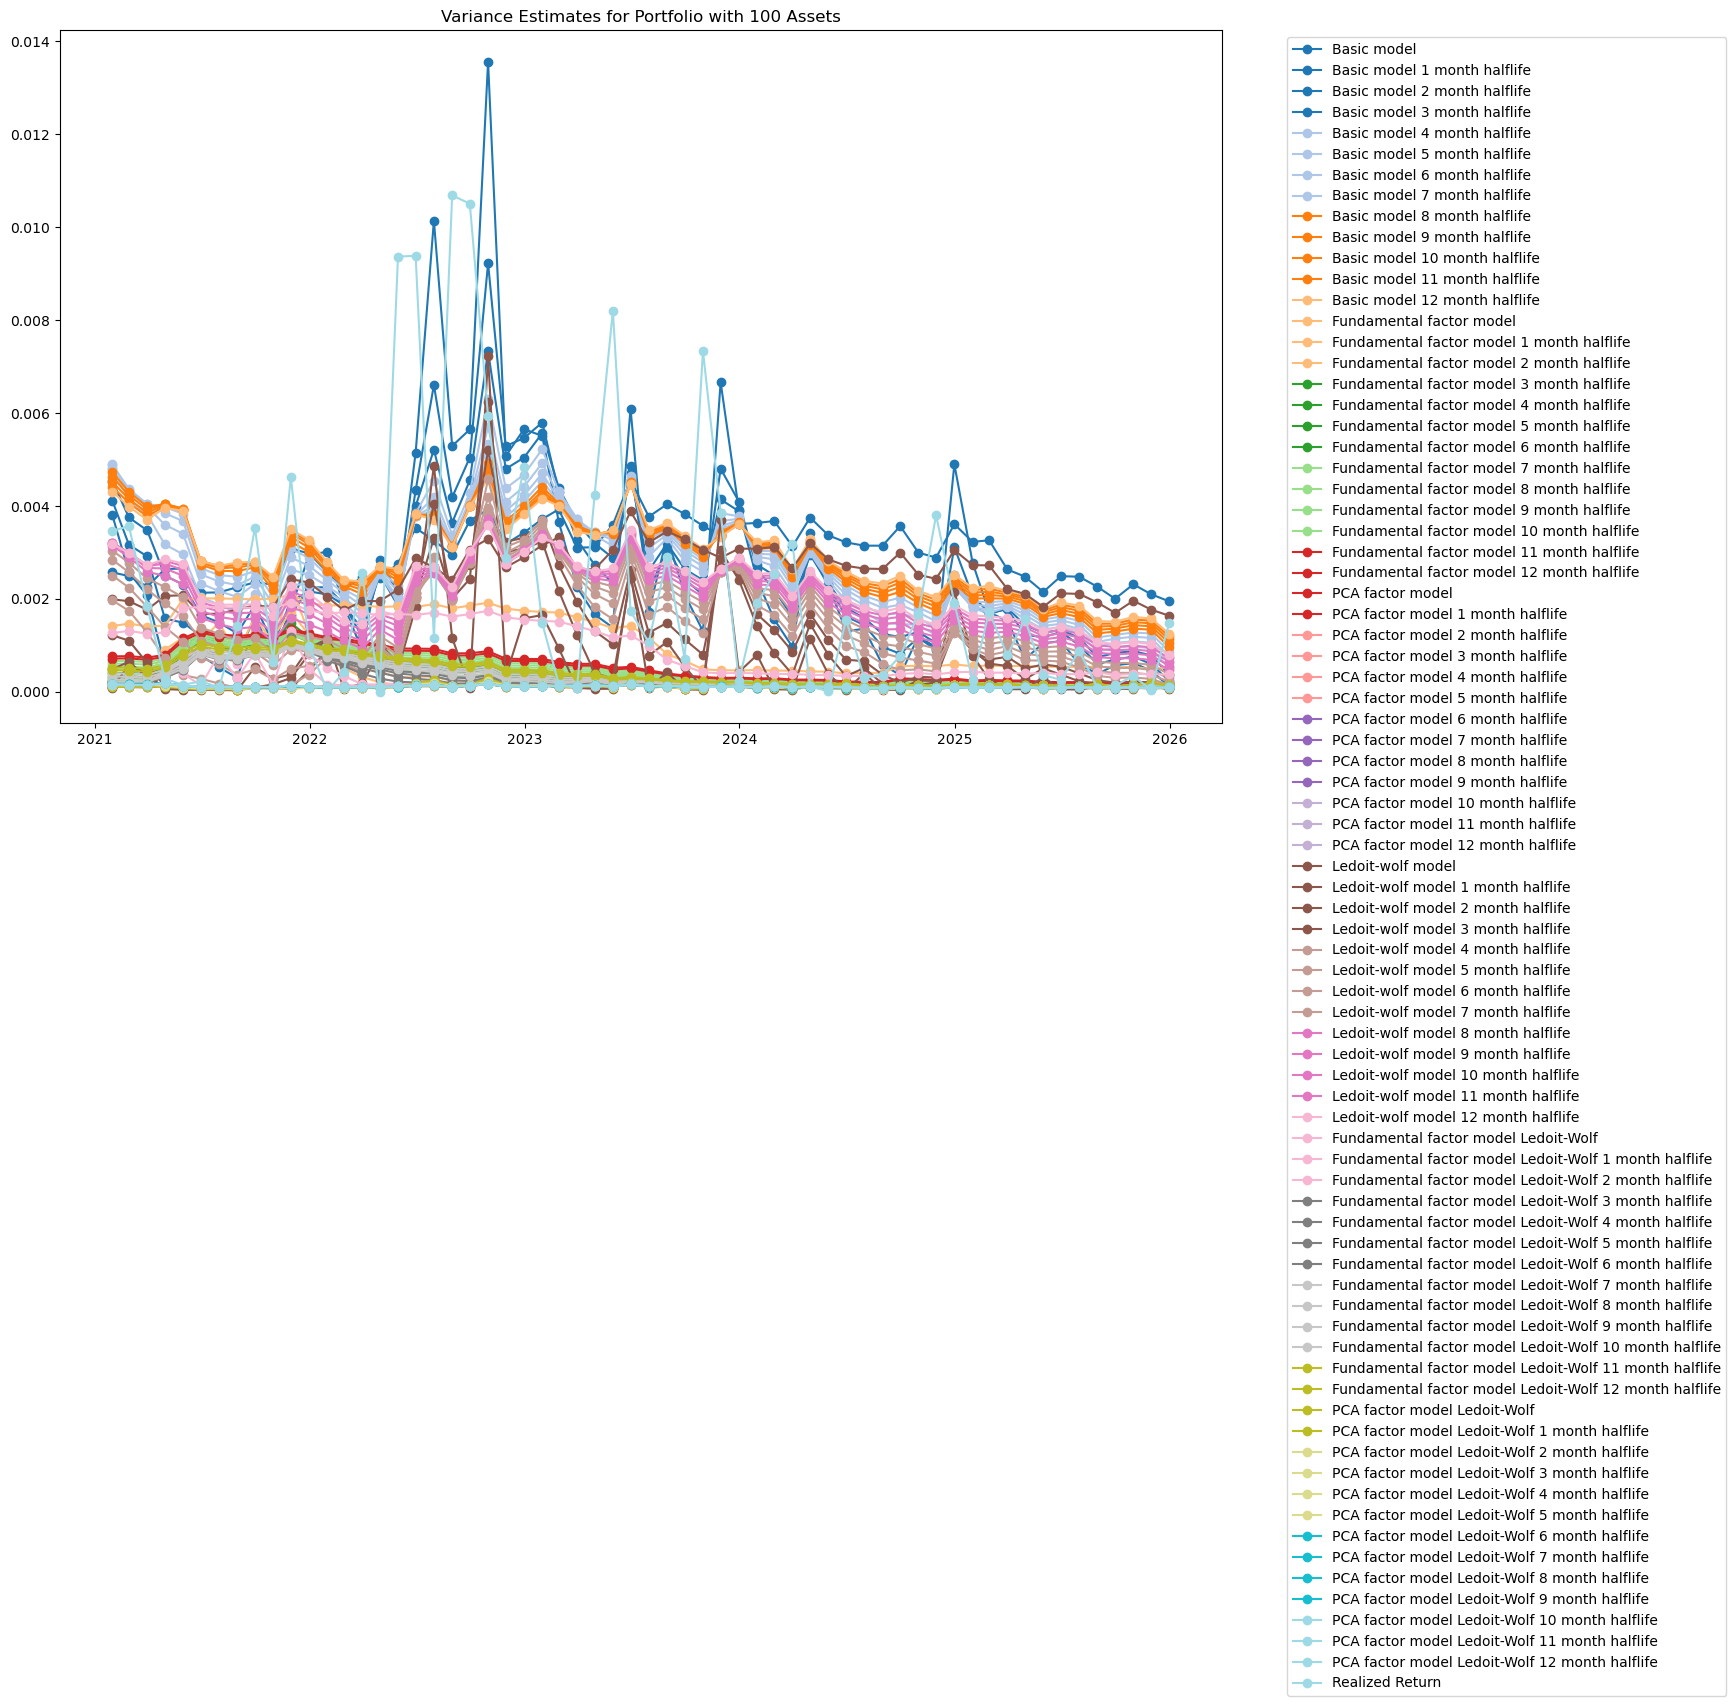

C:\Users\cblev\AppData\Local\Temp\ipykernel_3576\3337784882.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


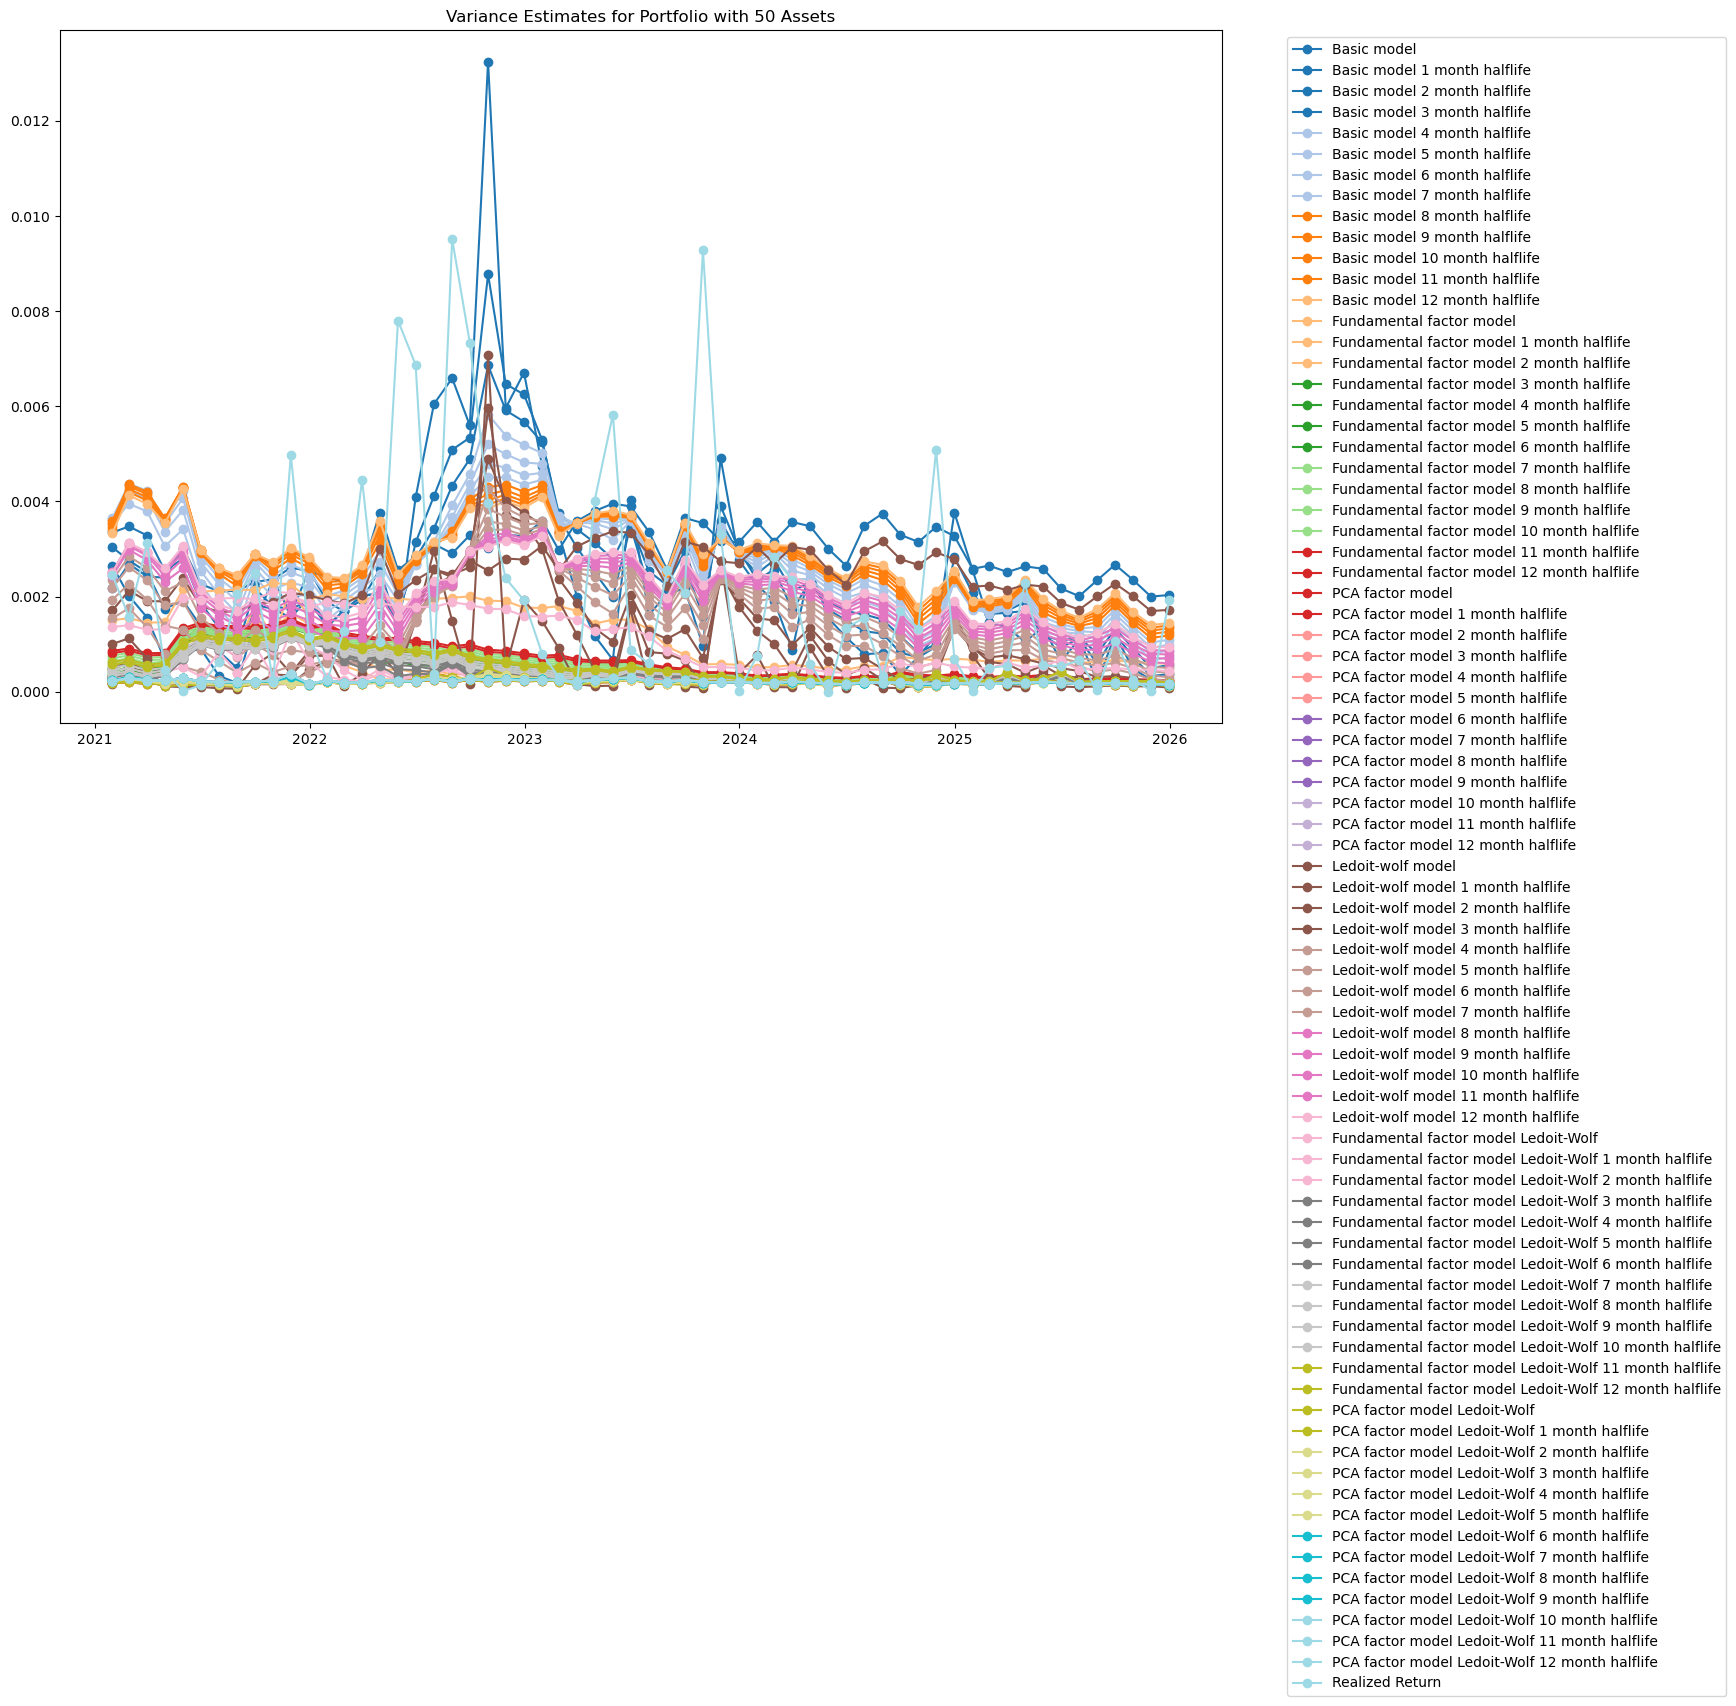

C:\Users\cblev\AppData\Local\Temp\ipykernel_3576\3337784882.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


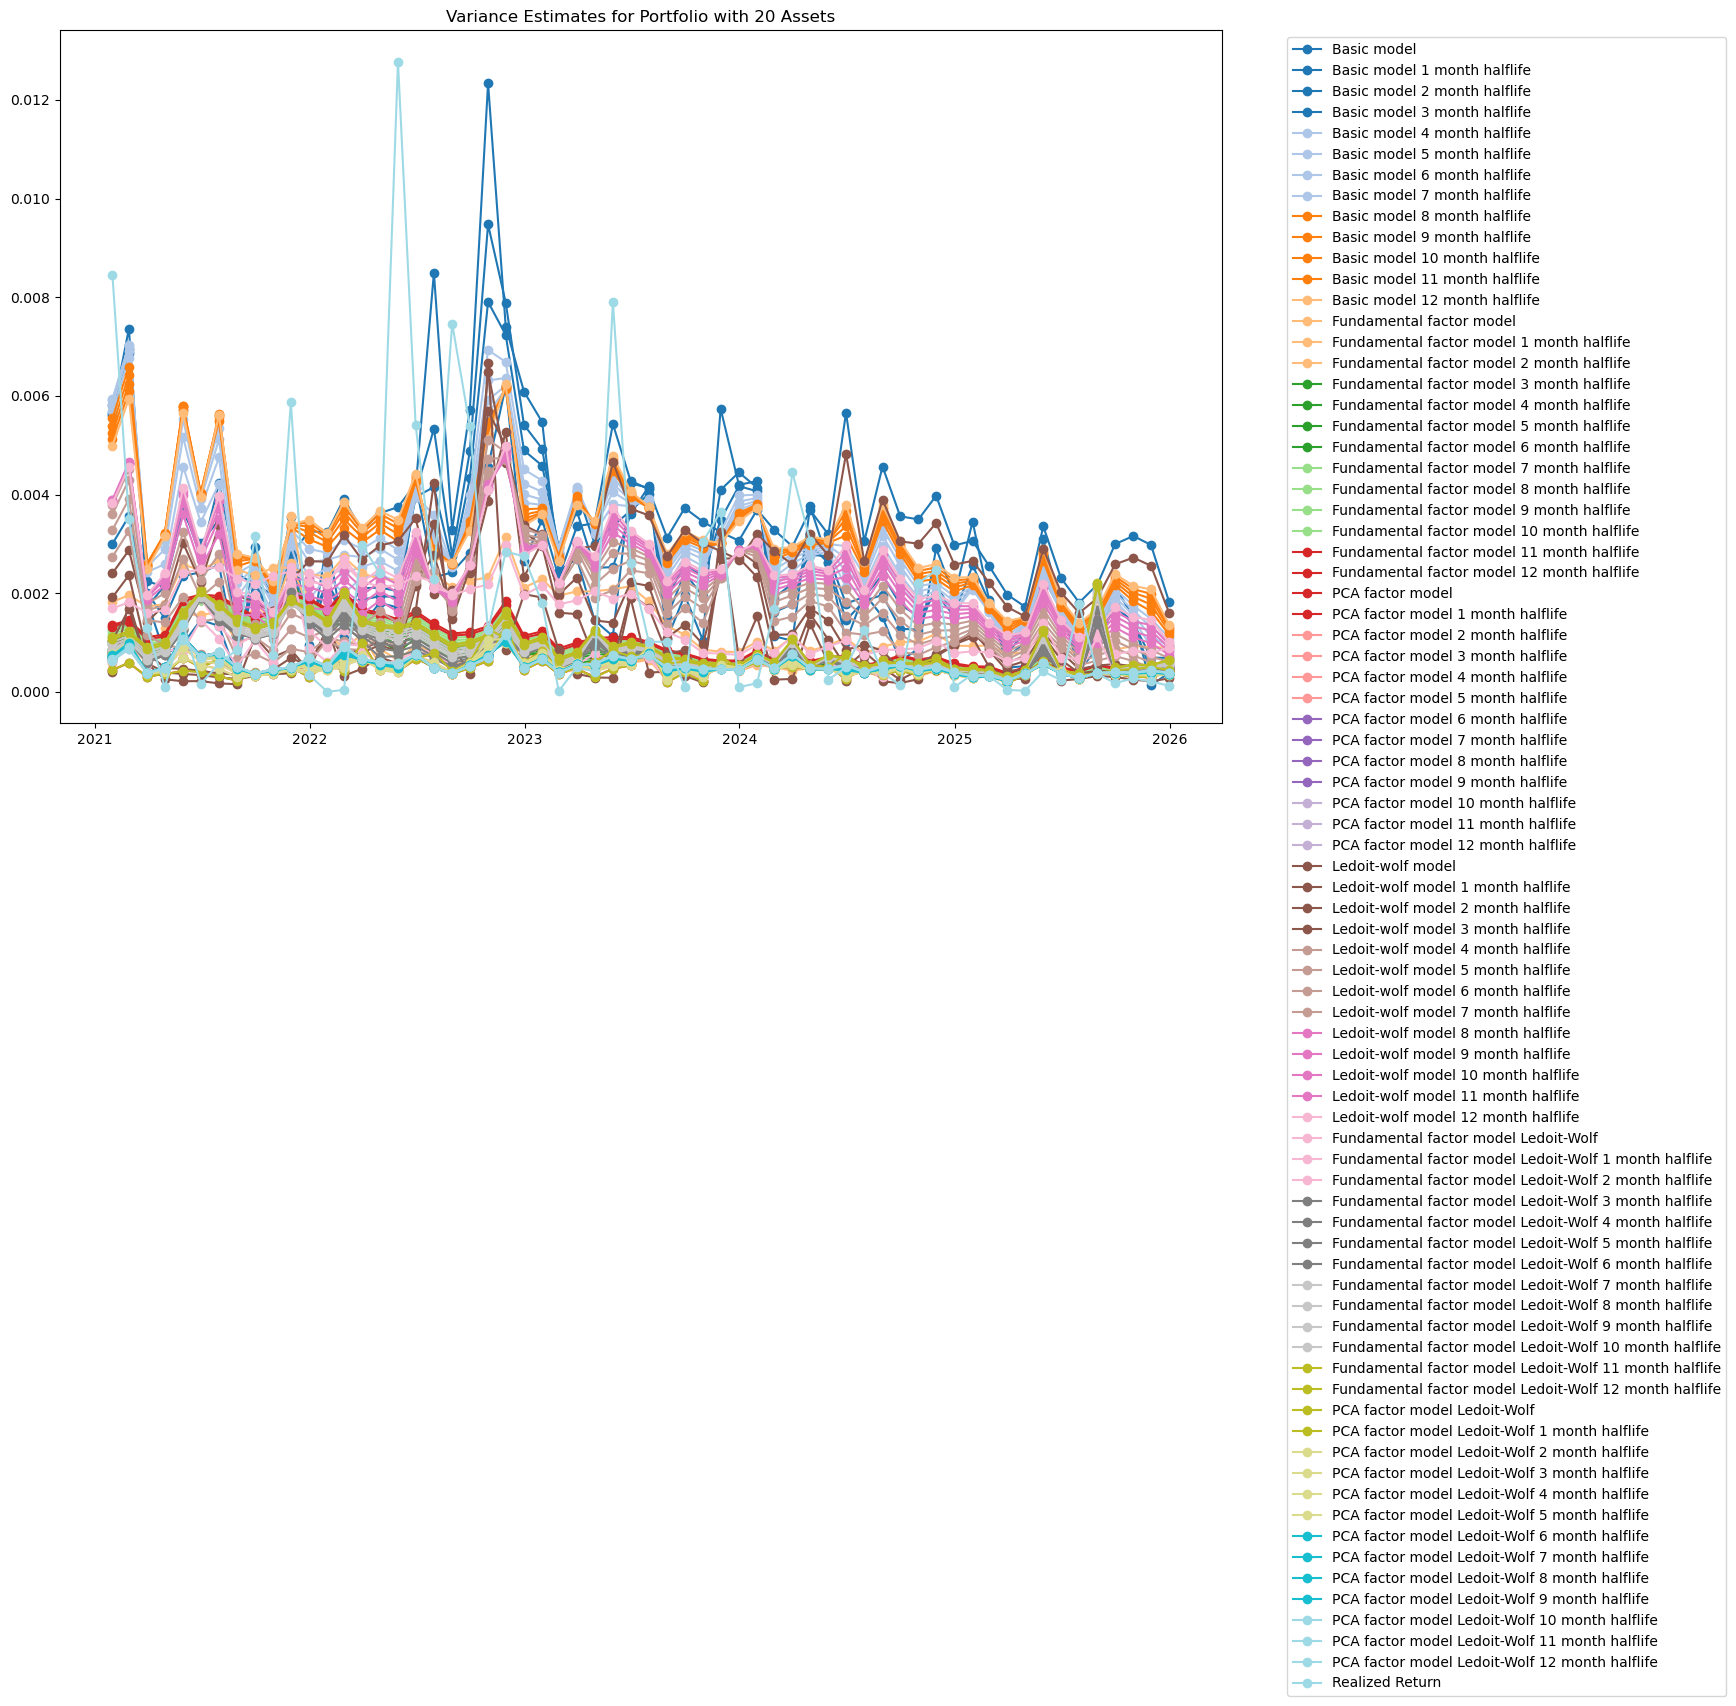

C:\Users\cblev\AppData\Local\Temp\ipykernel_3576\3337784882.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


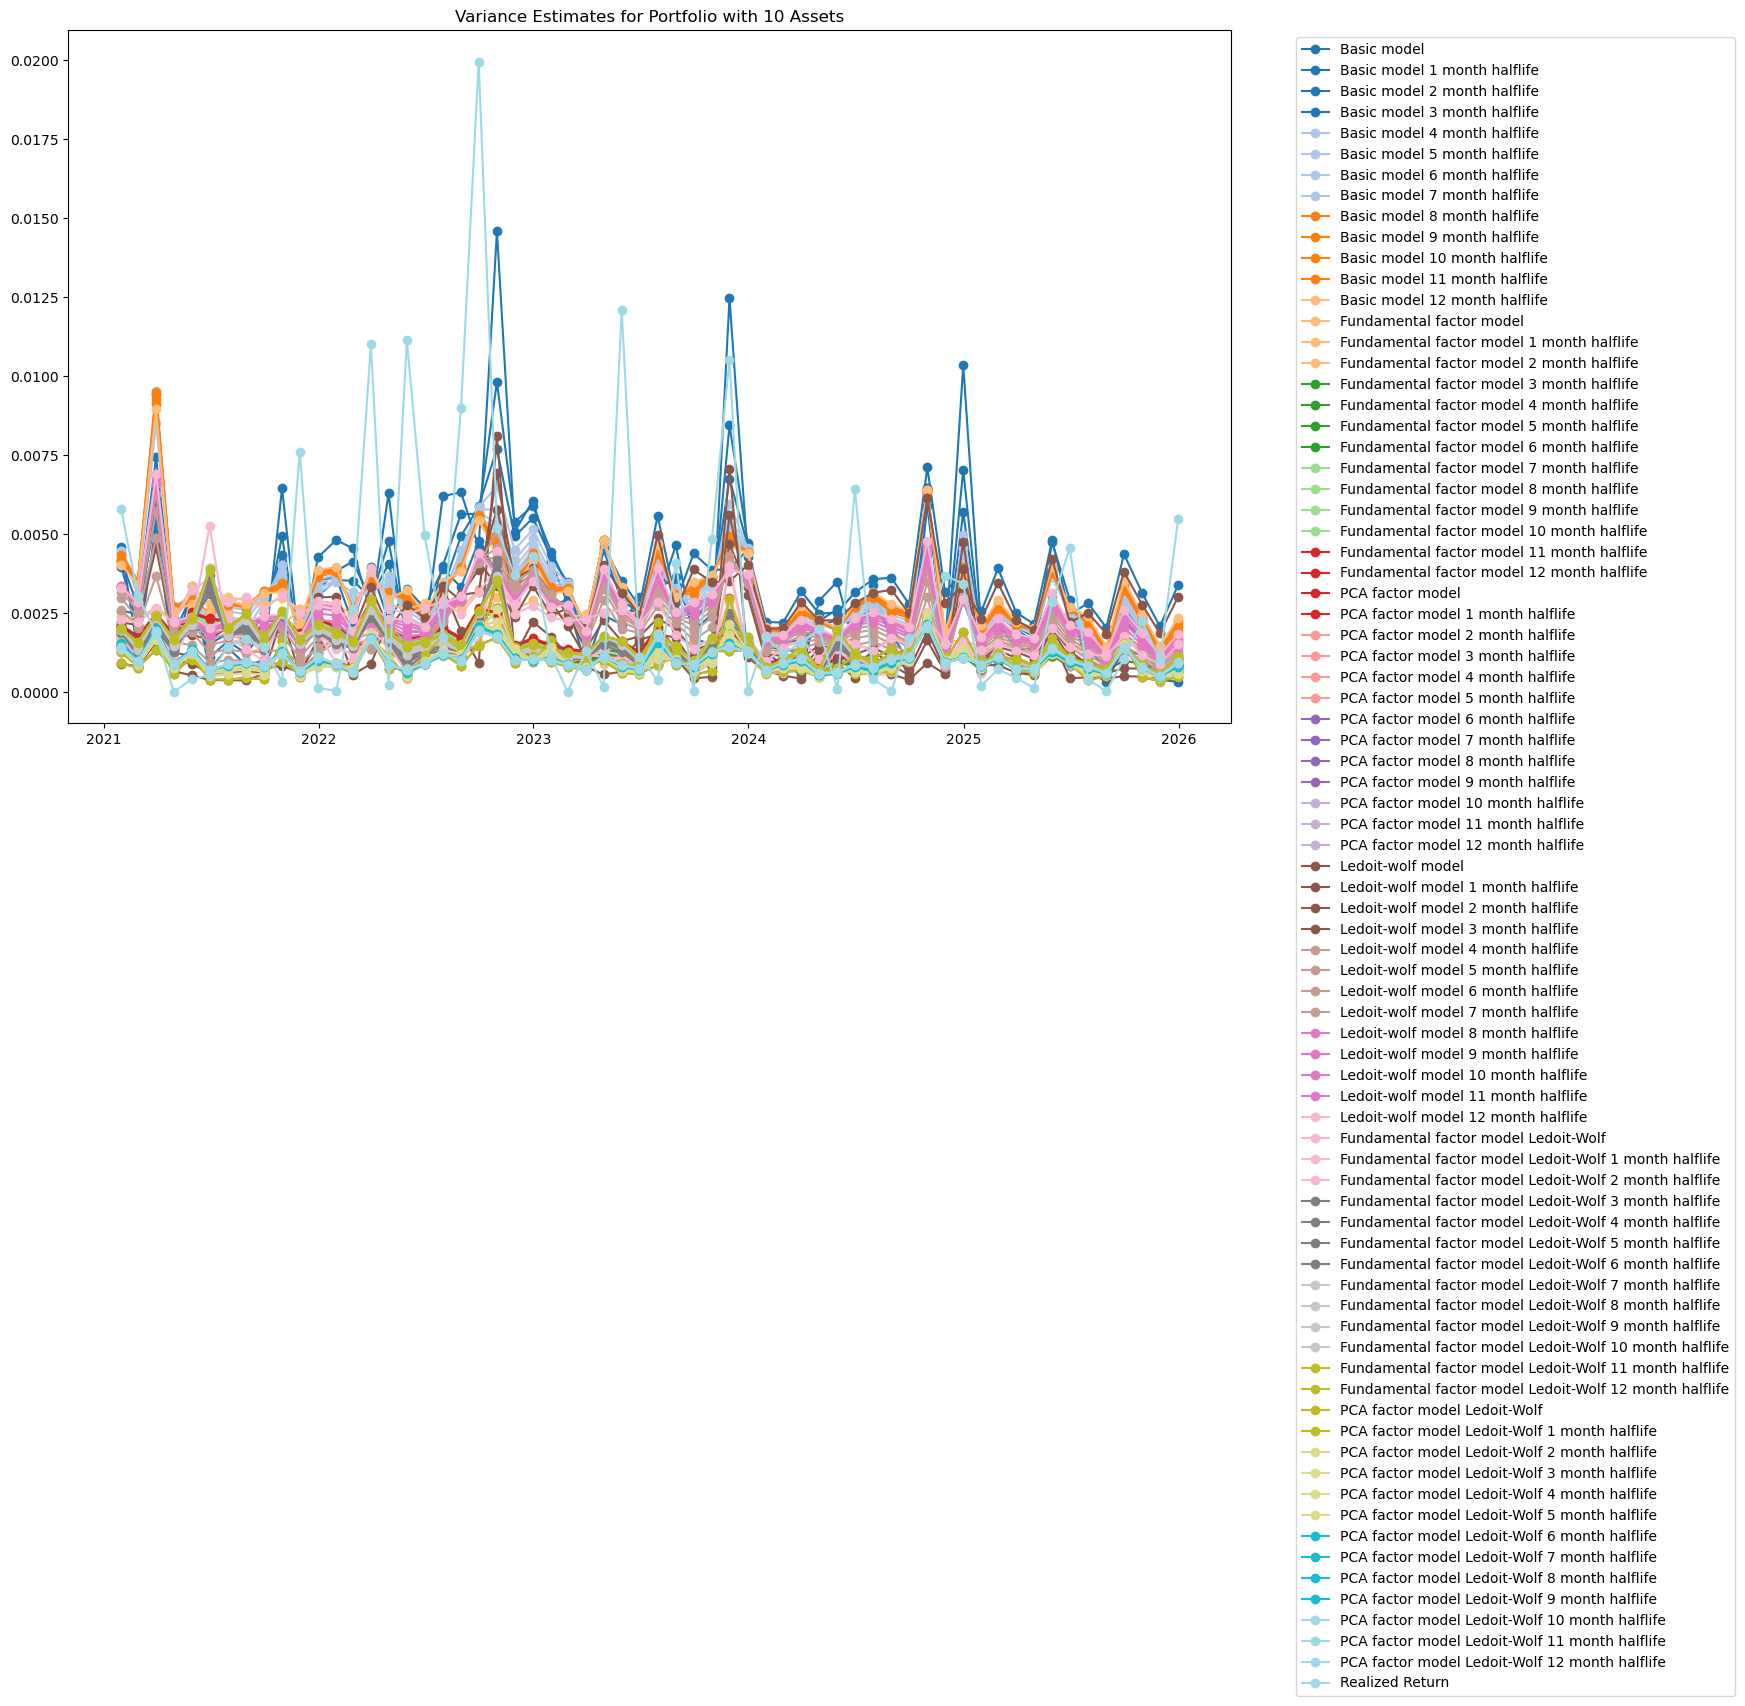

In [102]:
for n in n_assets:
    plot_volatility_estimates(trackers[n],models_dict,n)
    print("\n")